In [1]:
!pip install -q --upgrade pip
!pip install -q vllm>=0.6.3 huggingface_hub>=1.0 PyYAML>=6.0 openai>=1.40.0 rich>=13.0 tqdm>=4.66.3 matplotlib pandas numpy

import os
REPO_DIR = "/kaggle/working/IndicBankBench"
if not os.path.exists(REPO_DIR):
    !git clone https://github.com/npci/IndicBankBench.git {REPO_DIR}

%cd /kaggle/working/IndicBankBench
!pip install -q -e .
print("Cell 1 Complete: IndicBankBench installed in editable mode.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.65.0 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.3.0 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
Cloning into '/kaggle/working/IndicBankBench'...
remote: Enumerating objects: 966, done.
re

2

In [2]:
import os, json
from pathlib import Path
from huggingface_hub import login, snapshot_download
from kaggle_secrets import UserSecretsClient

# 1. Authenticate with Hugging Face
user_secrets = UserSecretsClient()
hf_token = user_secrets.get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = hf_token
login(token=hf_token)

# 2. Download the 799-case IndicBankBench dataset
DATA_DIR = "/kaggle/working/IndicBankBench/data"
os.makedirs(DATA_DIR, exist_ok=True)
snapshot_download(
    repo_id="NPCI/IndicBankBench",
    repo_type="dataset",
    local_dir=DATA_DIR,
    token=hf_token
)
os.environ["INDICBANKBENCH_DATA"] = DATA_DIR

# 3. Download Candidate Model into a local directory so we can set max_position_embeddings=16384
CANDIDATE_REPO = "CohereLabs/tiny-aya-fire"
CANDIDATE_LOCAL_DIR = "/kaggle/working/tiny-aya-fire-16k"
print(f"Downloading {CANDIDATE_REPO} to {CANDIDATE_LOCAL_DIR}...")
snapshot_download(
    repo_id=CANDIDATE_REPO,
    local_dir=CANDIDATE_LOCAL_DIR,
    token=hf_token
)

# Patch config.json max_position_embeddings -> 16384 so 32 tools + long RAG prompts never 400
cfg_path = Path(CANDIDATE_LOCAL_DIR) / "config.json"
cfg_data = json.loads(cfg_path.read_text())
old_max_pos = cfg_data.get("max_position_embeddings")
cfg_data["max_position_embeddings"] = 16384
cfg_path.write_text(json.dumps(cfg_data, indent=2))
print(f"Patched {cfg_path}: max_position_embeddings {old_max_pos} -> 16384")

# 4. Pre-download Judge Model
JUDGE_MODEL = "Qwen/Qwen2.5-7B-Instruct-AWQ"
print(f"Pre-downloading Judge Model: {JUDGE_MODEL}...")
snapshot_download(repo_id=JUDGE_MODEL, token=hf_token)

print("Cell 2 Complete: Dataset and both models are ready!")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 805 files:   0%|          | 0/805 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Patched /kaggle/working/tiny-aya-fire-16k/config.json: max_position_embeddings 8192 -> 16384
Pre-downloading Judge Model: Qwen/Qwen2.5-7B-Instruct-AWQ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Cell 2 Complete: Dataset and both models are ready!


3 

In [3]:
import os, re, yaml
from pathlib import Path

REPO_ROOT = Path("/kaggle/working/IndicBankBench")

# 1. Inspect original models.yaml so we see its exact structure
models_yaml = REPO_ROOT / "indicbankbench" / "config" / "models.yaml"
print("=== Original models.yaml ===")
print(models_yaml.read_text())

# 2. Replace 16384 and 16_384 across ALL code and config files (.py, .yaml, .yml, .json)
for ext in ("*.py", "*.yaml", "*.yml", "*.json"):
    for fpath in REPO_ROOT.rglob(ext):
        if "results" in fpath.parts or "data" in fpath.parts or ".git" in fpath.parts:
            continue
        txt = fpath.read_text(encoding="utf-8", errors="ignore")
        if "16384" in txt or "16_384" in txt:
            new_txt = txt.replace("16384", "1536").replace("16_384", "1536")
            fpath.write_text(new_txt, encoding="utf-8")
            print(f"Replaced 16384/16_384 -> 1536 in: {fpath.relative_to(REPO_ROOT)}")

# 3. Recursively update any max_tokens / max_completion_tokens key in models.yaml
def patch_dict_tokens(d):
    if isinstance(d, dict):
        for k, v in list(d.items()):
            if k in ("max_tokens", "max_completion_tokens") and isinstance(v, int) and v > 1536:
                d[k] = 1536
            else:
                patch_dict_tokens(v)
    elif isinstance(d, list):
        for item in d:
            patch_dict_tokens(item)

cfg = yaml.safe_load(models_yaml.read_text()) or {}
patch_dict_tokens(cfg)
models_yaml.write_text(yaml.safe_dump(cfg, sort_keys=False))

print("\n=== Patched models.yaml ===")
print(models_yaml.read_text())

# 4. Install sitecustomize.py so ANY OpenAI chat.completions.create call in any subprocess
# automatically clamps max_tokens / max_completion_tokens to 1536
sitecustomize_code = """import openai.resources.chat.completions as _cc

_orig_create = _cc.Completions.create
def _safe_create(self, *args, **kwargs):
    if kwargs.get("max_tokens") is not None and kwargs["max_tokens"] > 1536:
        kwargs["max_tokens"] = 1536
    if kwargs.get("max_completion_tokens") is not None and kwargs["max_completion_tokens"] > 1536:
        kwargs["max_completion_tokens"] = 1536
    if "max_tokens" not in kwargs and "max_completion_tokens" not in kwargs:
        kwargs["max_tokens"] = 1536
    return _orig_create(self, *args, **kwargs)
_cc.Completions.create = _safe_create

if hasattr(_cc, "AsyncCompletions"):
    _orig_acreate = _cc.AsyncCompletions.create
    async def _safe_acreate(self, *args, **kwargs):
        if kwargs.get("max_tokens") is not None and kwargs["max_tokens"] > 1536:
            kwargs["max_tokens"] = 1536
        if kwargs.get("max_completion_tokens") is not None and kwargs["max_completion_tokens"] > 1536:
            kwargs["max_completion_tokens"] = 1536
        if "max_tokens" not in kwargs and "max_completion_tokens" not in kwargs:
            kwargs["max_tokens"] = 1536
        return await _orig_acreate(self, *args, **kwargs)
    _cc.AsyncCompletions.create = _safe_acreate
"""

(REPO_ROOT / "sitecustomize.py").write_text(sitecustomize_code)
(REPO_ROOT / "indicbankbench" / "sitecustomize.py").write_text(sitecustomize_code)
os.environ["PYTHONPATH"] = f"{REPO_ROOT}:{REPO_ROOT / 'indicbankbench'}:" + os.environ.get("PYTHONPATH", "")

# 5. Write .env configuration
env_content = """JUDGE_BASE_URL=http://127.0.0.1:8001/v1
JUDGE_MODEL=judge-model
JUDGE_API_KEY=EMPTY
CANDIDATE_BASE_URL=http://127.0.0.1:8000/v1
CANDIDATE_MODEL=tiny-aya-fire
CANDIDATE_API_KEY=EMPTY
INDICBANKBENCH_DATA=/kaggle/working/IndicBankBench/data
"""
(REPO_ROOT / ".env").write_text(env_content)
(REPO_ROOT / "indicbankbench" / ".env").write_text(env_content)
for line in env_content.strip().splitlines():
    k, v = line.split("=", 1)
    os.environ[k] = v

print("Cell 3 Complete: All token limits clamped to 1536 and .env configured.")

=== Original models.yaml ===
models:

  candidate_default:
    provider: "openai"
    model: "${CANDIDATE_MODEL:-/model}"
    api_key_env: "CANDIDATE_API_KEY"
    base_url: "${CANDIDATE_BASE_URL}"
    temperature: 0.7
    max_tokens: 16384
    top_p: 1.0
    # seed: 42
    request_timeout: 600
    max_retries: ${MODEL_MAX_RETRIES:-2}

  judge_default:
    provider: "openai"
    model: "${JUDGE_MODEL:-/model}"
    api_key_env: "JUDGE_API_KEY"
    base_url: "${JUDGE_BASE_URL}"
    max_tokens: 32768
    request_timeout: 300
    max_retries: ${MODEL_MAX_RETRIES:-2}

  report_default:
    provider: "openai"
    model: "${JUDGE_MODEL:-/model}"
    api_key_env: "JUDGE_API_KEY"
    base_url: "${JUDGE_BASE_URL}"
    temperature: 0.3
    max_tokens: 32768
    top_p: 1.0
    request_timeout: 300
    max_retries: ${MODEL_MAX_RETRIES:-2}

Replaced 16384/16_384 -> 1536 in: indicbankbench/config/models.yaml

=== Patched models.yaml ===
models:
  candidate_default:
    provider: openai
    model: ${CA

#### 4

In [4]:
import os, time, subprocess, requests
from pathlib import Path
from openai import OpenAI

!pkill -9 -f "vllm.entrypoints.openai.api_server" || true
time.sleep(3)

CANDIDATE_LOCAL_DIR = "/kaggle/working/tiny-aya-fire-16k"
JUDGE_MODEL = "Qwen/Qwen2.5-7B-Instruct-AWQ"

# Robust Jinja template handling system, user, assistant (with tool_calls), and tool roles
TOOL_CHAT_TEMPLATE = "/kaggle/working/cohere_tool_template.jinja"
with open(TOOL_CHAT_TEMPLATE, "w") as f:
    f.write("""{{ bos_token }}{% if messages[0]['role'] == 'system' %}<|START_OF_TURN_TOKEN|><|SYSTEM_TOKEN|>{{ messages[0]['content'] or '' }}{% if tools %}\n\n# Available Tools\nYou may call one or more functions to assist with the user query. You are provided with function signatures within <tools></tools> XML tags:\n<tools>\n{% for tool in tools %}{{ tool | tojson }}\n{% endfor %}</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{"name": <function-name>, "arguments": <args-json-object>}\n</tool_call>{% endif %}<|END_OF_TURN_TOKEN|>{% set loop_messages = messages[1:] %}{% else %}{% set loop_messages = messages %}{% if tools %}<|START_OF_TURN_TOKEN|><|SYSTEM_TOKEN|># Available Tools\nYou may call one or more functions to assist with the user query. You are provided with function signatures within <tools></tools> XML tags:\n<tools>\n{% for tool in tools %}{{ tool | tojson }}\n{% endfor %}</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{"name": <function-name>, "arguments": <args-json-object>}\n</tool_call><|END_OF_TURN_TOKEN|>{% endif %}{% endif %}{% for message in loop_messages %}{% if message['role'] == 'user' %}<|START_OF_TURN_TOKEN|><|USER_TOKEN|>{{ message['content'] or '' }}<|END_OF_TURN_TOKEN|>{% elif message['role'] == 'assistant' %}<|START_OF_TURN_TOKEN|><|CHATBOT_TOKEN|>{% if message.get('content') %}{{ message['content'] }}{% endif %}{% if message.get('tool_calls') %}{% for tc in message['tool_calls'] %}<tool_call>\n{"name": "{{ tc['function']['name'] }}", "arguments": {{ tc['function']['arguments'] if tc['function']['arguments'] is string else (tc['function']['arguments'] | tojson) }}}\n</tool_call>{% endfor %}{% endif %}<|END_OF_TURN_TOKEN|>{% elif message['role'] == 'tool' %}<|START_OF_TURN_TOKEN|><|SYSTEM_TOKEN|><tool_response>\n{{ message['content'] or '' }}\n</tool_response><|END_OF_TURN_TOKEN|>{% elif message['role'] == 'system' %}<|START_OF_TURN_TOKEN|><|SYSTEM_TOKEN|>{{ message['content'] or '' }}<|END_OF_TURN_TOKEN|>{% endif %}{% endfor %}<|START_OF_TURN_TOKEN|><|CHATBOT_TOKEN|>""")

# 1. Launch Candidate Server on T4 GPU 0 (Port 8000, max_model_len=16384)
env_gpu0 = os.environ.copy()
env_gpu0["CUDA_VISIBLE_DEVICES"] = "0"
env_gpu0["VLLM_ALLOW_LONG_MAX_MODEL_LEN"] = "1"

candidate_cmd = [
    "python", "-m", "vllm.entrypoints.openai.api_server",
    "--model", CANDIDATE_LOCAL_DIR,
    "--served-model-name", "tiny-aya-fire",
    "--dtype", "half",
    "--max-model-len", "16384",
    "--gpu-memory-utilization", "0.90",
    "--enforce-eager",
    "--enable-auto-tool-choice",
    "--tool-call-parser", "hermes",
    "--chat-template", TOOL_CHAT_TEMPLATE,
    "--port", "8000",
    "--trust-remote-code"
]

candidate_proc = subprocess.Popen(
    candidate_cmd,
    env=env_gpu0,
    stdout=open("/kaggle/working/vllm_candidate.log", "w"),
    stderr=subprocess.STDOUT
)

# 2. Launch Judge Server on T4 GPU 1 (Port 8001, max_model_len=16384)
env_gpu1 = os.environ.copy()
env_gpu1["CUDA_VISIBLE_DEVICES"] = "1"

judge_cmd = [
    "python", "-m", "vllm.entrypoints.openai.api_server",
    "--model", JUDGE_MODEL,
    "--served-model-name", "judge-model",
    "--quantization", "awq",
    "--dtype", "half",
    "--max-model-len", "16384",
    "--gpu-memory-utilization", "0.90",
    "--enforce-eager",
    "--port", "8001",
    "--trust-remote-code"
]

judge_proc = subprocess.Popen(
    judge_cmd,
    env=env_gpu1,
    stdout=open("/kaggle/working/vllm_judge.log", "w"),
    stderr=subprocess.STDOUT
)

def wait_for_server(url, name, log_path, timeout=600):
    start = time.time()
    while time.time() - start < timeout:
        try:
            r = requests.get(f"{url}/v1/models", timeout=5)
            if r.status_code == 200:
                print(f"[READY] {name} is live at {url}/v1")
                return True
        except Exception:
            pass
        time.sleep(5)
    print(f"=== ERROR LOG FOR {name} ===")
    print(Path(log_path).read_text()[-3000:])
    raise RuntimeError(f"Timeout waiting for {name}")

print("Waiting for Candidate (GPU 0) and Judge (GPU 1) vLLM servers...")
wait_for_server("http://127.0.0.1:8000", "Candidate (tiny-aya-fire 16K)", "/kaggle/working/vllm_candidate.log")
wait_for_server("http://127.0.0.1:8001", "Judge (Qwen2.5-7B-Instruct-AWQ)", "/kaggle/working/vllm_judge.log")

Waiting for Candidate (GPU 0) and Judge (GPU 1) vLLM servers...
[READY] Candidate (tiny-aya-fire 16K) is live at http://127.0.0.1:8000/v1
[READY] Judge (Qwen2.5-7B-Instruct-AWQ) is live at http://127.0.0.1:8001/v1


True

5

In [5]:
import json
from pathlib import Path

%cd /kaggle/working/IndicBankBench

print("=== Step 1: Running 1-Case Pre-Flight Check ===")
!PYTHONPATH=/kaggle/working/IndicBankBench:/kaggle/working/IndicBankBench/indicbankbench python -m harness.cli run \
    --run-id preflight_check \
    --passes 1 \
    --cases /kaggle/working/IndicBankBench/data/case_bank/accounts_and_transactions/agentic/balance_gate.002.json \
    --fresh

# Verify 0 errors in preflight_check before launching full 799-case run
preflight_err_file = Path("/kaggle/working/IndicBankBench/indicbankbench/results/preflight_check/cases/pass1/errors.jsonl")
if preflight_err_file.exists() and preflight_err_file.read_text().strip():
    print("\n[!] PRE-FLIGHT CHECK ERROR DETECTED:")
    print(preflight_err_file.read_text())
    print("\n--- Last 25 lines of vllm_candidate.log ---")
    !tail -n 25 /kaggle/working/vllm_candidate.log
    print("\n--- Last 25 lines of vllm_judge.log ---")
    !tail -n 25 /kaggle/working/vllm_judge.log
    raise RuntimeError("Stopping before full run because preflight_check had an error. See traceback above.")
else:
    print("\n[OK] Pre-flight check completed with E:0 (Zero Errors)! Launching full 799-case x 3-pass benchmark...")

!PYTHONPATH=/kaggle/working/IndicBankBench:/kaggle/working/IndicBankBench/indicbankbench python -m harness.cli run \
    --run-id tiny_aya_fire_full \
    --passes 3 \
    --concurrency 4 \
    --fresh

/kaggle/working/IndicBankBench
=== Step 1: Running 1-Case Pre-Flight Check ===
run preflight_check: 1 cases x 1 pass(es) -> tiny-aya-fire @ temp 0.7, prompt indicbankbench/prompts/base_system_prompt.txt (a95f38458240)
pass 1/1: 100%|████████████████████████████████████| 1/1 [00:35<00:00, 35.93s/case, P:0 F:1 E:0 C:0]
  pass 1/1: 1 ran, 0 cached, 0 errored
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                          Eval run — preflight_check                          ┃
┗━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┛

 • candidate: tiny-aya-fire  (temp 0.7)  http://127.0.0.1:8000/v1               
 • judge: judge-model                                                           
 • passes: 1   cases: 1   started: 2026-11-15 04:27:03                          
 • report generated: 2026-11-15 04:27                                           


                               pass^1 — 0/1 (0%)                        

######  6 

In [6]:
import json
from pathlib import Path

RESULT_DIR = Path("/kaggle/working/IndicBankBench/indicbankbench/results/tiny_aya_fire_full")
TOTAL_BENCHMARK_CASES = 799

summary_path = RESULT_DIR / "summary.json"
report_path = RESULT_DIR / "REPORT.md"

summary = json.loads(summary_path.read_text())
strict_pass_n = int(summary.get("strict_pass", 0))
pass_at_3_n = int(summary.get("any_pass", 0))
mean_single_pct = round(float(summary.get("mean_single_shot", 0.0)) * (100.0 if float(summary.get("mean_single_shot", 0.0)) <= 1.0 else 1.0), 1)

strict_pass_pct = round((strict_pass_n / TOTAL_BENCHMARK_CASES) * 100.0, 1)
pass_at_3_pct = round((pass_at_3_n / TOTAL_BENCHMARK_CASES) * 100.0, 1)
gap_pct = round(pass_at_3_pct - strict_pass_pct, 1)

tiny_aya_fire_metrics = {
    "model": "Tiny-Aya-Fire (3.35B)",
    "strict_pass_n": strict_pass_n,
    "strict_pass_pct": strict_pass_pct,
    "pass_at_3_n": pass_at_3_n,
    "pass_at_3_pct": pass_at_3_pct,
    "gap_pct": gap_pct,
    "mean_single_pct": mean_single_pct,
    "fail_reasons": summary.get("fail_reasons", {})
}

print("=== Official REPORT.md ===")
if report_path.exists():
    print(report_path.read_text()[:3500])

print("\n=== Extracted Tiny-Aya-Fire Metrics ===")
print(json.dumps(tiny_aya_fire_metrics, indent=2))

=== Official REPORT.md ===
# Eval run — `tiny_aya_fire_full`

- candidate: **tiny-aya-fire**  (temp 0.7)  `http://127.0.0.1:8000/v1`
- judge: judge-model
- passes: **3**   cases: **799**   started: 2026-11-15 04:27:41
- report generated: 2026-11-15 10:12

## pass^3 — **24/799 (3%)**

| metric | value |
|---|---|
| pass^3 | **24/799 (3%)** |
| pass@3 | 134/799 (17%) |
| mean | 9% |
| avg@3 | 13% |

## pass^3 by domain

| domain | pass^3 | total | rate |
|---|---|---|---|
| accounts_and_transactions | 4 | 138 | 3% |
| calculators | 3 | 90 | 3% |
| capability | 6 | 68 | 9% |
| cards | 2 | 103 | 2% |
| customer_service_and_catalog | 4 | 178 | 2% |
| deposits_and_loans | 5 | 222 | 2% |

## pass^3 by axis

| axis | pass^3 | total | rate |
|---|---|---|---|
| 10_unseen_tools | 0 | 14 | 0% |
| 11_out_of_scope_refuse | 1 | 40 | 2% |
| 1_happy_path | 2 | 39 | 5% |
| 2_bad_tool_response | 0 | 36 | 0% |
| 3_confusing_intent | 0 | 53 | 0% |
| 4_not_enough_info | 0 | 61 | 0% |
| 5_contradicting_info

7 

=== Full IndicBankBench Leaderboard (799 Cases) ===


,model,strict_pass_n,strict_pass_pct,pass_at_3_n,pass_at_3_pct,gap_pct
Rank,,,,,,
1,DeepSeek-V4-Pro-0813,465,58.2,574,71.8,13.6
2,Grok 4.6,464,58.1,561,70.2,12.1
3,Qwen3.8-2.4T-A95B,462,57.8,591,74.0,16.1
4,Claude Opus 5,461,57.7,570,71.3,13.6
5,GLM-5.3-Flash,454,56.8,594,74.3,17.5
6,DeepSeek-V4-Flash-0731,433,54.2,580,72.6,18.4
7,Gemma 4 31B IT,432,54.1,525,65.7,11.6
8,Gemini 3.8 Flash,426,53.3,512,64.1,10.8
9,MiniMax M3,385,48.2,556,69.6,21.4


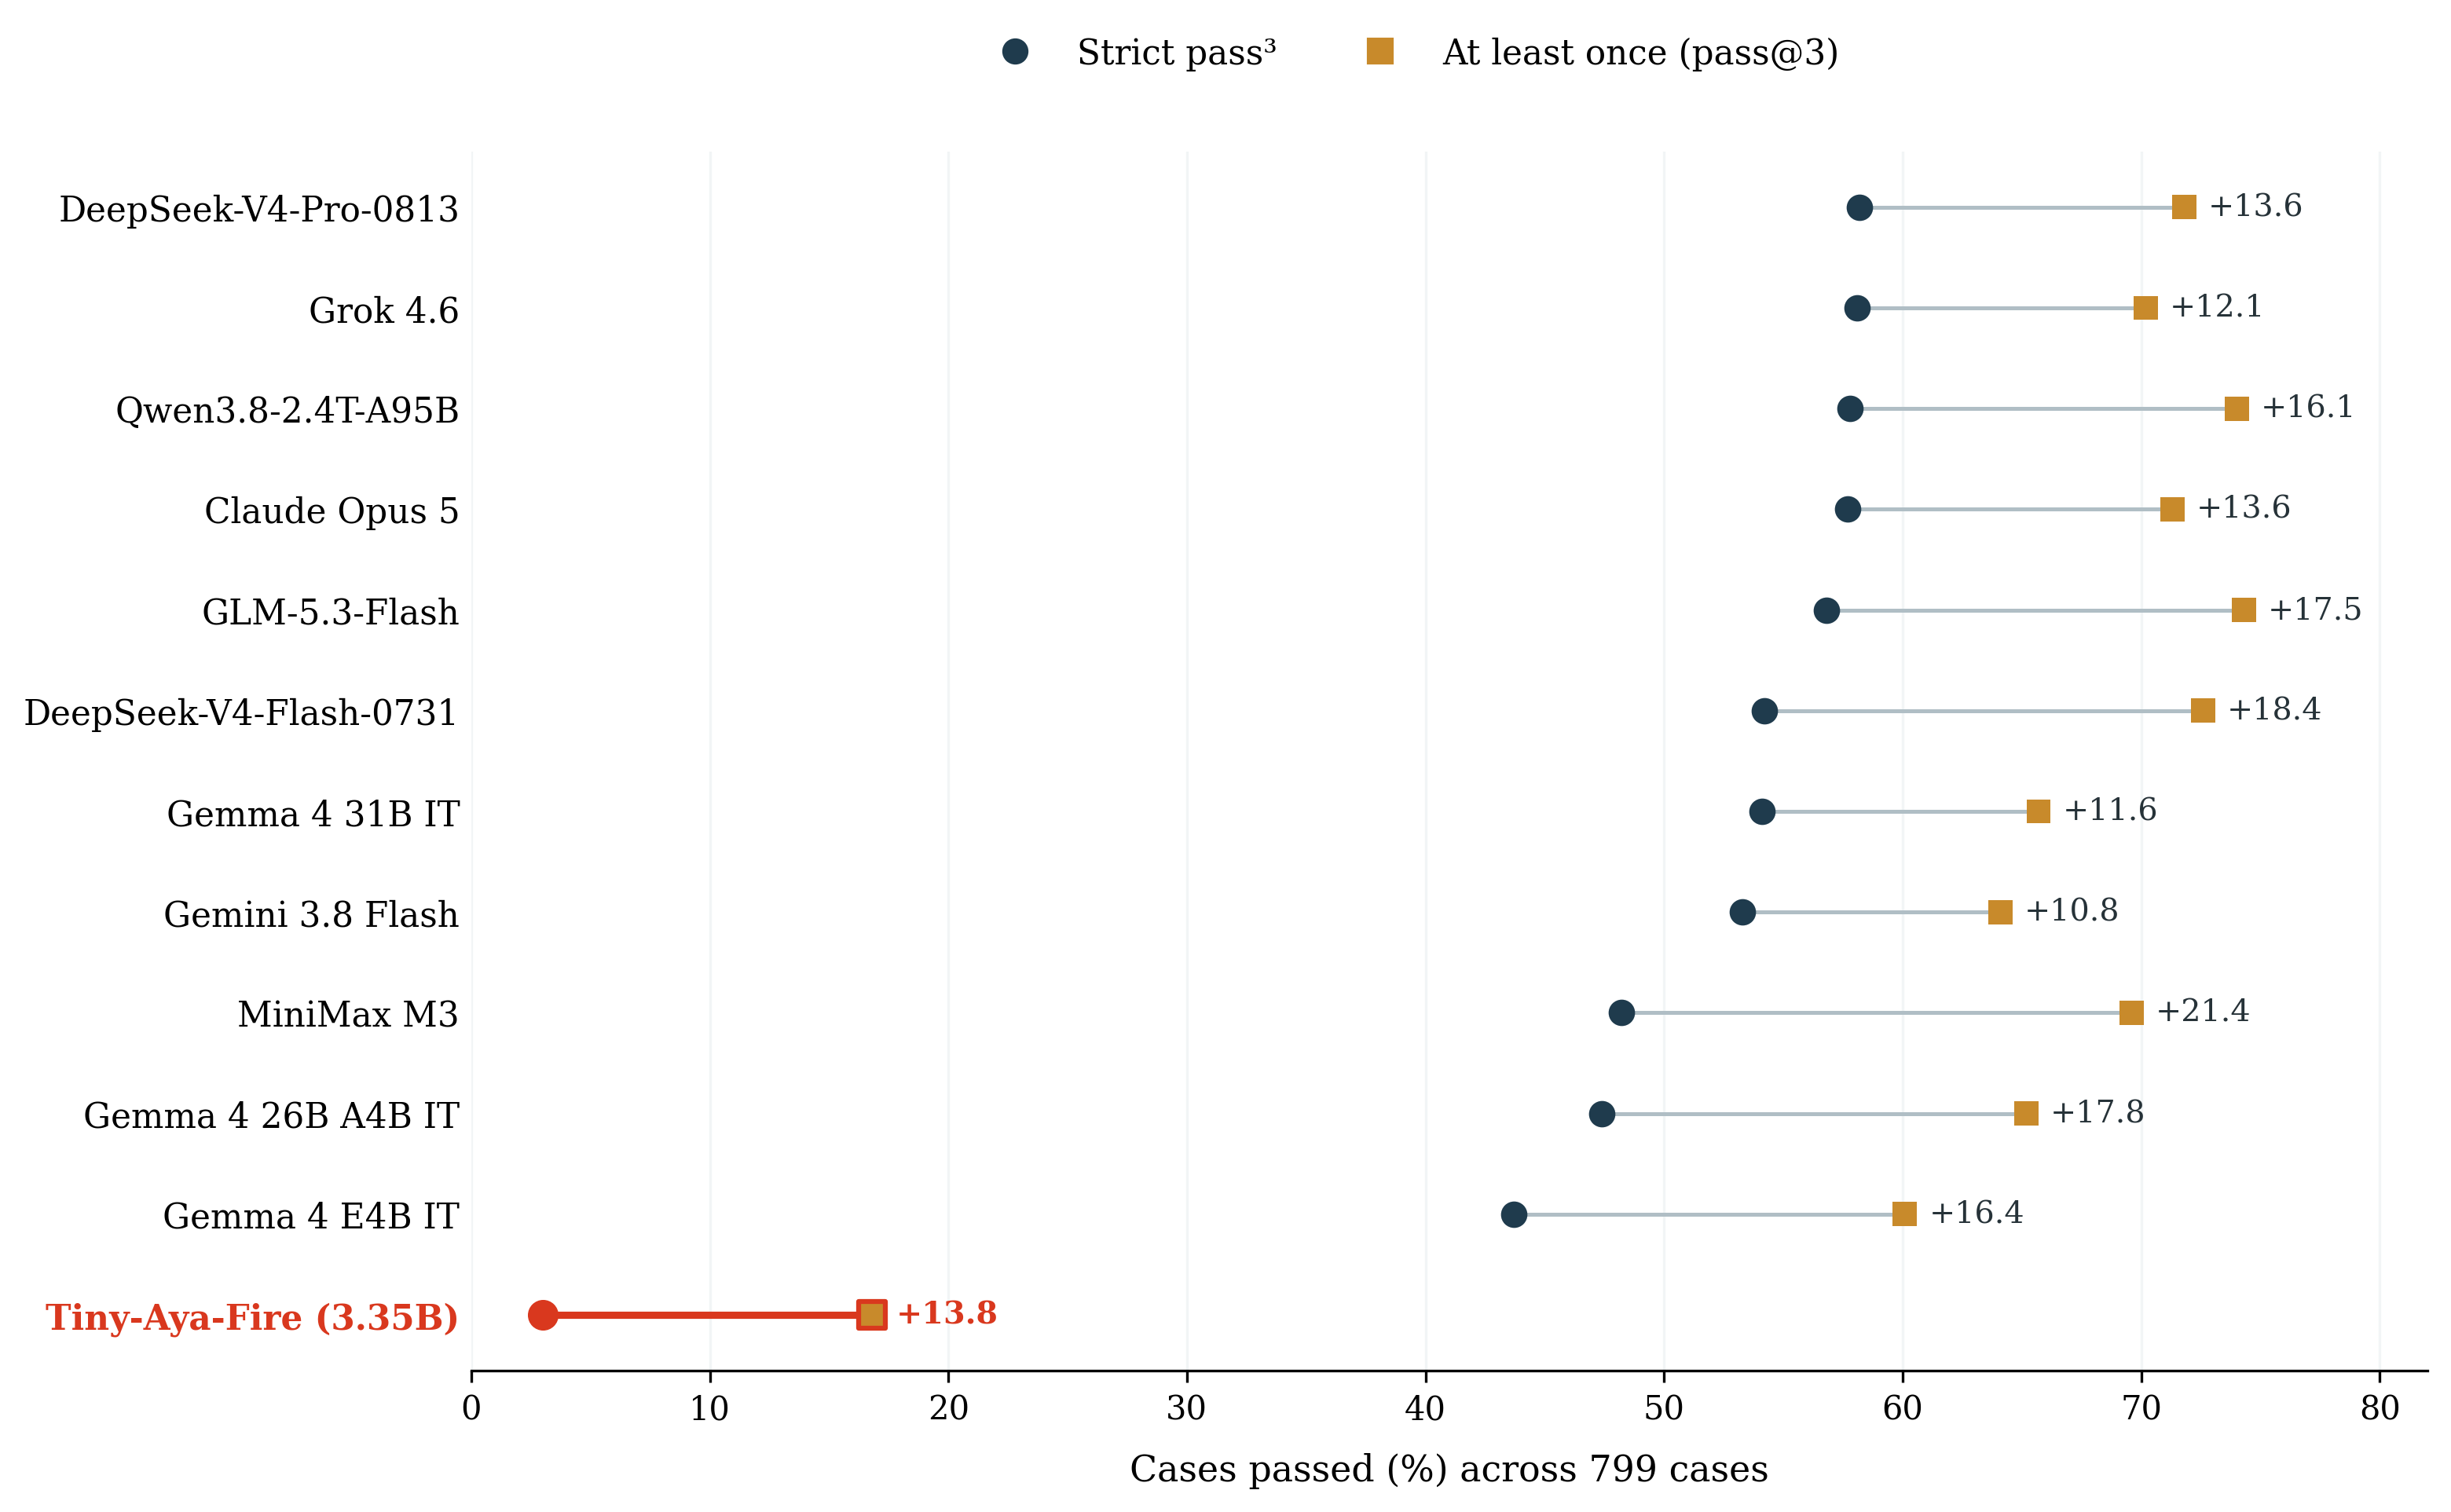

In [7]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import pandas as pd
import numpy as np

PAPER_BASELINES = [
    {"model": "DeepSeek-V4-Pro-0813",   "strict_pass_n": 465, "strict_pass_pct": 58.2, "pass_at_3_n": 574, "pass_at_3_pct": 71.8, "gap_pct": 13.6},
    {"model": "Grok 4.6",               "strict_pass_n": 464, "strict_pass_pct": 58.1, "pass_at_3_n": 561, "pass_at_3_pct": 70.2, "gap_pct": 12.1},
    {"model": "Qwen3.8-2.4T-A95B",      "strict_pass_n": 462, "strict_pass_pct": 57.8, "pass_at_3_n": 591, "pass_at_3_pct": 74.0, "gap_pct": 16.1},
    {"model": "Claude Opus 5",          "strict_pass_n": 461, "strict_pass_pct": 57.7, "pass_at_3_n": 570, "pass_at_3_pct": 71.3, "gap_pct": 13.6},
    {"model": "GLM-5.3-Flash",          "strict_pass_n": 454, "strict_pass_pct": 56.8, "pass_at_3_n": 594, "pass_at_3_pct": 74.3, "gap_pct": 17.5},
    {"model": "DeepSeek-V4-Flash-0731", "strict_pass_n": 433, "strict_pass_pct": 54.2, "pass_at_3_n": 580, "pass_at_3_pct": 72.6, "gap_pct": 18.4},
    {"model": "Gemma 4 31B IT",         "strict_pass_n": 432, "strict_pass_pct": 54.1, "pass_at_3_n": 525, "pass_at_3_pct": 65.7, "gap_pct": 11.6},
    {"model": "Gemini 3.8 Flash",       "strict_pass_n": 426, "strict_pass_pct": 53.3, "pass_at_3_n": 512, "pass_at_3_pct": 64.1, "gap_pct": 10.8},
    {"model": "MiniMax M3",             "strict_pass_n": 385, "strict_pass_pct": 48.2, "pass_at_3_n": 556, "pass_at_3_pct": 69.6, "gap_pct": 21.4},
    {"model": "Gemma 4 26B A4B IT",     "strict_pass_n": 379, "strict_pass_pct": 47.4, "pass_at_3_n": 521, "pass_at_3_pct": 65.2, "gap_pct": 17.8},
    {"model": "Gemma 4 E4B IT",         "strict_pass_n": 349, "strict_pass_pct": 43.7, "pass_at_3_n": 480, "pass_at_3_pct": 60.1, "gap_pct": 16.4},
]

candidate_row = {
    "model": tiny_aya_fire_metrics["model"],
    "strict_pass_n": tiny_aya_fire_metrics["strict_pass_n"],
    "strict_pass_pct": tiny_aya_fire_metrics["strict_pass_pct"],
    "pass_at_3_n": tiny_aya_fire_metrics["pass_at_3_n"],
    "pass_at_3_pct": tiny_aya_fire_metrics["pass_at_3_pct"],
    "gap_pct": tiny_aya_fire_metrics["gap_pct"],
}

df_leaderboard = pd.DataFrame(PAPER_BASELINES + [candidate_row]).sort_values(
    by="strict_pass_pct", ascending=False
).reset_index(drop=True)
df_leaderboard.index = df_leaderboard.index + 1
df_leaderboard.index.name = "Rank"

print("=== Full IndicBankBench Leaderboard (799 Cases) ===")
display(df_leaderboard)

df_plot = df_leaderboard.sort_values(by="strict_pass_pct", ascending=True).reset_index(drop=True)

plt.rcParams["font.family"] = "serif"
fig, ax = plt.subplots(figsize=(10.5, 6.5), dpi=300)

y_pos = np.arange(len(df_plot))
NAVY_DOT = "#1f3b4d"
GOLD_SQUARE = "#c88a2b"
LINE_COLOR = "#b0bec5"
HIGHLIGHT_FIRE = "#d9381e"

ax.xaxis.grid(True, linestyle="-", alpha=0.25, color="#cfd8dc", zorder=0)
ax.set_axisbelow(True)

for idx, row in df_plot.iterrows():
    is_cand = "Tiny-Aya-Fire" in row["model"]
    line_col = HIGHLIGHT_FIRE if is_cand else LINE_COLOR
    lw = 2.2 if is_cand else 1.2

    ax.plot([row["strict_pass_pct"], row["pass_at_3_pct"]], [idx, idx], color=line_col, linewidth=lw, zorder=2)
    ax.scatter(row["strict_pass_pct"], idx, color=HIGHLIGHT_FIRE if is_cand else NAVY_DOT, s=70 if is_cand else 50, marker="o", zorder=3)
    ax.scatter(row["pass_at_3_pct"], idx, color=GOLD_SQUARE, edgecolors=HIGHLIGHT_FIRE if is_cand else "none", linewidths=1.5 if is_cand else 0, s=70 if is_cand else 55, marker="s", zorder=3)

    gap_sign = "+" if row["gap_pct"] >= 0 else ""
    ax.text(
        row["pass_at_3_pct"] + 1.0, idx, f"{gap_sign}{row['gap_pct']:.1f}",
        va="center", ha="left", fontsize=9.5,
        fontweight="bold" if is_cand else "normal",
        color=HIGHLIGHT_FIRE if is_cand else "#263238"
    )

ax.set_yticks(y_pos)
yticklabels = ax.set_yticklabels(df_plot["model"], fontsize=10.5)
for label in yticklabels:
    if "Tiny-Aya-Fire" in label.get_text():
        label.set_color(HIGHLIGHT_FIRE)
        label.set_fontweight("bold")

min_score = min(df_plot["strict_pass_pct"].min(), 40.0)
x_min = max(0.0, np.floor((min_score - 5.0) / 5.0) * 5.0) if min_score < 40.0 else 40.0
ax.set_xlim(x_min, 82)
ax.set_xlabel("Cases passed (%) across 799 cases", fontsize=11, labelpad=8)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)

strict_handle = mlines.Line2D([], [], color=NAVY_DOT, marker="o", linestyle="None", markersize=7, label="Strict pass³")
pass3_handle = mlines.Line2D([], [], color=GOLD_SQUARE, marker="s", linestyle="None", markersize=7, label="At least once (pass@3)")
ax.legend(handles=[strict_handle, pass3_handle], loc="upper center", bbox_to_anchor=(0.48, 1.12), ncol=2, frameon=False, fontsize=10.5)

plt.tight_layout()
plt.savefig("/kaggle/working/indicbankbench_tiny_aya_fire_figure3.png", dpi=300, bbox_inches="tight")
plt.show()

8 

In [8]:
candidate_proc.terminate()
judge_proc.terminate()
print("vLLM servers stopped cleanly.")

vLLM servers stopped cleanly.
